<a href="https://colab.research.google.com/github/taniasahu/Deep-Learning-Based-RFF-for-Cross-Day-and-Cross-Receiver-Transmitter-Identification/blob/main/Cross_Rx_RF_Fingerprinting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import h5py
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from google.colab import drive
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from tensorflow import keras
from tensorflow.keras import layers

In [ ]:
SEED = 0
EPOCHS = 40
BATCH_SIZE = 256
PREDICT_BATCH_SIZE = 1024

NUM_CLASSES = 6
NUM_RECEIVERS = 12
RECEIVERS_PER_PAIR = 2
NUM_FOLDS = NUM_RECEIVERS // RECEIVERS_PER_PAIR
SAMPLES_PER_SIGNAL = 256  # I/Q samples per example (256 I values + 256 Q values)

CLASS_NAMES = ["14-10", "14-7", "20-15", "20-19", "6-15", "8-20"]
RECEIVER_NAMES = ["1-1", "1-19", "14-7", "18-2", "19-2", "2-1",
                  "2-19", "20-1", "3-19", "7-14", "7-7", "8-8"]

keras.utils.set_random_seed(SEED)


def receiver_label(receiver_id):
    """Receiver ids are 1-based; names are stored in a 0-based list."""
    return RECEIVER_NAMES[receiver_id - 1]

In [ ]:
def load_split(split_name):
    """Load one .mat split and return (iq_flat, transmitter_labels, receiver_ids)."""
    path = os.path.join(DATA_DIR, f"{split_name}.mat")
    with h5py.File(path, "r") as mat_file:
        # MATLAB stores arrays transposed relative to NumPy
        iq_flat = np.array(mat_file[f"X_{split_name}"]).T.astype(np.float32)  # (N, 512)
        transmitters = np.array(mat_file[f"meta_{split_name}/tx"]).squeeze().astype(np.int64) - 1  # 0..5
        receivers = np.array(mat_file[f"meta_{split_name}/rx"]).squeeze().astype(np.int64)  # 1..12
    return iq_flat, transmitters, receivers


def load_dataset():
    """Merge train/val/test files (the day-based splits are ignored) into (N, 256, 2) arrays."""
    splits = [load_split(name) for name in ("train", "val", "test")]
    iq_flat = np.concatenate([split[0] for split in splits])
    transmitters = np.concatenate([split[1] for split in splits])
    receivers = np.concatenate([split[2] for split in splits])

    # Channel 0 = I, channel 1 = Q
    iq_signals = np.stack([iq_flat[:, :SAMPLES_PER_SIGNAL], iq_flat[:, SAMPLES_PER_SIGNAL:]], axis=-1)
    return iq_signals, transmitters, receivers

In [ ]:
class RandomPhase(layers.Layer):
    """Rotates I/Q by a random phase, during training only.

    Each receiver has its own phase offset, so randomizing it pushes the model
    to ignore the offset rather than memorize it.
    """

    def call(self, iq_batch, training=None):
        if not training:
            return iq_batch

        batch_size = tf.shape(iq_batch)[0]
        phase = tf.random.uniform((batch_size, 1), 0.0, 2.0 * np.pi)
        in_phase, quadrature = iq_batch[..., 0], iq_batch[..., 1]

        rotated_in_phase = in_phase * tf.cos(phase) - quadrature * tf.sin(phase)
        rotated_quadrature = in_phase * tf.sin(phase) + quadrature * tf.cos(phase)
        return tf.stack([rotated_in_phase, rotated_quadrature], axis=-1)


def conv_block(x, filters, kernel_size, pool=True):
    x = layers.Conv1D(filters, kernel_size, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    if pool:
        x = layers.MaxPool1D(2)(x)
    return x


def create_cnn():
    inputs = keras.Input(shape=(SAMPLES_PER_SIGNAL, 2))
    x = RandomPhase()(inputs)

    x = conv_block(x, 32, 7)
    x = conv_block(x, 64, 5)
    x = conv_block(x, 128, 3)
    x = conv_block(x, 128, 3, pool=False)

    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)


def build_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
    ]

In [ ]:
def make_receiver_pairs(rng):
    """Shuffle all receivers once and split them into disjoint pairs."""
    all_receivers = np.arange(1, NUM_RECEIVERS + 1)
    return rng.permutation(all_receivers).reshape(NUM_FOLDS, RECEIVERS_PER_PAIR)


def sample_indices_for(receiver_ids, sample_receivers):
    return np.where(np.isin(sample_receivers, receiver_ids))[0]


def train_and_predict(iq_signals, transmitters, train_idx, val_idx, test_idx):
    """Train on train_idx, early-stop on val_idx, and predict classes for test_idx."""
    model = create_cnn()
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    model.fit(
        iq_signals[train_idx], transmitters[train_idx],
        validation_data=(iq_signals[val_idx], transmitters[val_idx]),
        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2,
        callbacks=build_callbacks(),
    )
    probabilities = model.predict(iq_signals[test_idx], batch_size=PREDICT_BATCH_SIZE, verbose=0)
    return probabilities.argmax(axis=1)


def run_cross_validation(iq_signals, transmitters, receivers):
    """Return per-fold accuracies plus pooled true labels, predictions and receiver ids."""
    receiver_pairs = make_receiver_pairs(np.random.RandomState(SEED))

    fold_accuracies = []
    pooled_true, pooled_pred, pooled_receivers = [], [], []

    for fold, test_receivers in enumerate(receiver_pairs):
        # Rotating the pairs gives each fold a different validation pair
        val_receivers = receiver_pairs[(fold + 1) % NUM_FOLDS]
        held_out_receivers = np.concatenate([test_receivers, val_receivers])
        train_receivers = np.setdiff1d(np.arange(1, NUM_RECEIVERS + 1), held_out_receivers)

        train_idx = sample_indices_for(train_receivers, receivers)
        val_idx = sample_indices_for(val_receivers, receivers)
        test_idx = sample_indices_for(test_receivers, receivers)

        print("\n")
        print(f"Fold {fold}: test receivers = {[receiver_label(r) for r in test_receivers]} | "
              f"val receivers = {[receiver_label(r) for r in val_receivers]}")
        print(f"Train {len(train_idx)} | Val {len(val_idx)} | Test {len(test_idx)}")

        predictions = train_and_predict(iq_signals, transmitters, train_idx, val_idx, test_idx)
        accuracy = accuracy_score(transmitters[test_idx], predictions)
        print(f"Test accuracy on unseen receivers: {accuracy:.4f}")

        fold_accuracies.append(accuracy)
        pooled_true.append(transmitters[test_idx])
        pooled_pred.append(predictions)
        pooled_receivers.append(receivers[test_idx])

    return (fold_accuracies,
            np.concatenate(pooled_true),
            np.concatenate(pooled_pred),
            np.concatenate(pooled_receivers))

In [ ]:
def print_report(fold_accuracies, y_true, y_pred, test_receivers):
    print(f"Accuracy per fold: {[round(accuracy, 4) for accuracy in fold_accuracies]}")
    print(f"Mean accuracy : {np.mean(fold_accuracies):.4f} +/- {np.std(fold_accuracies):.4f}")
    print(f"Macro F1 : {f1_score(y_true, y_pred, average='macro'):.4f}\n")

    print("classification report\n")
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

    print("Accuracy per unseen receiver:")
    for receiver_id in np.unique(test_receivers):
        is_this_receiver = test_receivers == receiver_id
        accuracy = accuracy_score(y_true[is_this_receiver], y_pred[is_this_receiver])
        print(f"  {receiver_label(receiver_id):>5}: {accuracy:.4f}")


def plot_confusion_matrix(y_true, y_pred):
    matrix = confusion_matrix(y_true, y_pred)
    text_color_threshold = matrix.max() / 2

    plt.figure(figsize=(6, 5))
    plt.imshow(matrix, cmap="Blues")
    plt.colorbar()
    plt.title("Confusion Matrix (unseen receivers)")
    plt.xlabel("Predicted Transmitter")
    plt.ylabel("Actual Transmitter")
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
    plt.yticks(range(NUM_CLASSES), CLASS_NAMES)

    for row in range(NUM_CLASSES):
        for col in range(NUM_CLASSES):
            text_color = "white" if matrix[row, col] > text_color_threshold else "black"
            plt.text(col, row, matrix[row, col], ha="center", va="center", color=text_color)

    plt.tight_layout()
    plt.show()


In [ ]:
drive.mount('/content/drive')
DATA_DIR = "/content/drive/MyDrive/Dataprocess"
print(os.listdir(DATA_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['dataset_info.mat', 'test.mat', 'train.mat', 'val.mat']


In [ ]:
iq_signals, transmitters, receivers = load_dataset()
print("Data:", iq_signals.shape, "| Transmitters:", np.unique(transmitters), "| Receivers:", np.unique(receivers))
print("NaN:", np.isnan(iq_signals).sum(), "| Inf:", np.isinf(iq_signals).sum())

Data: (288000, 256, 2) | Transmitters: [0 1 2 3 4 5] | Receivers: [ 1  2  3  4  5  6  7  8  9 10 11 12]
NaN: 0 | Inf: 0


In [ ]:
create_cnn().summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 256, 2)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_phase_4 (RandomPhase)    │ (None, 256, 2)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_16 (Conv1D)              │ (None, 256, 32)        │           480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 256, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_16 (Activation)      │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_12 (MaxPooling1D) │ (None, 128, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_17 (Conv1D)              │ (None, 128, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 128, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_17 (Activation)      │ (None, 128, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_13 (MaxPooling1D) │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_18 (Conv1D)              │ (None, 64, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 64, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_18 (Activation)      │ (None, 64, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_14 (MaxPooling1D) │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_19 (Conv1D)              │ (None, 32, 128)        │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 32, 128)        │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_19 (Activation)      │ (None, 32, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 103,462 (404.15 KB)

 Trainable params: 102,758 (401.40 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
fold_accuracies, y_true, y_pred, test_receivers = run_cross_validation(iq_signals, transmitters, receivers)



Fold 0: test receivers = ['2-19', '8-8'] | val receivers = ['19-2', '7-7']
Train 192000 | Val 48000 | Test 48000
Epoch 1/40
750/750 - 17s - 22ms/step - accuracy: 0.7386 - loss: 0.6516 - val_accuracy: 0.5951 - val_loss: 1.3984 - learning_rate: 0.0010
Epoch 2/40
750/750 - 7s - 9ms/step - accuracy: 0.9301 - loss: 0.2134 - val_accuracy: 0.7491 - val_loss: 0.8304 - learning_rate: 0.0010
Epoch 3/40
750/750 - 7s - 9ms/step - accuracy: 0.9567 - loss: 0.1363 - val_accuracy: 0.5886 - val_loss: 1.1626 - learning_rate: 0.0010
Epoch 4/40
750/750 - 7s - 9ms/step - accuracy: 0.9657 - loss: 0.1103 - val_accuracy: 0.6046 - val_loss: 1.8968 - learning_rate: 0.0010
Epoch 5/40
750/750 - 7s - 10ms/step - accuracy: 0.9772 - loss: 0.0733 - val_accuracy: 0.7737 - val_loss: 0.7043 - learning_rate: 5.0000e-04
Epoch 6/40
750/750 - 7s - 9ms/step - accuracy: 0.9793 - loss: 0.0676 - val_accuracy: 0.6207 - val_loss: 1.9435 - learning_rate: 5.0000e-04
Epoch 7/40
750/750 - 7s - 10ms/step - accuracy: 0.9798 - loss: 0

In [ ]:
print_report(fold_accuracies, y_true, y_pred, test_receivers)

Accuracy per fold: [0.7076, 0.762, 0.5859, 0.6047, 0.5693, 0.7983]
Mean accuracy : 0.6713 +/- 0.0893
Macro F1 : 0.6726

classification report

              precision    recall  f1-score   support

       14-10     0.6081    0.8058    0.6931     48000
        14-7     0.6467    0.5326    0.5841     48000
       20-15     0.7111    0.5826    0.6405     48000
       20-19     0.4786    0.5598    0.5160     48000
        6-15     0.8658    0.8096    0.8368     48000
        8-20     0.7953    0.7373    0.7652     48000

    accuracy                         0.6713    288000
   macro avg     0.6843    0.6713    0.6726    288000
weighted avg     0.6843    0.6713    0.6726    288000

Accuracy per unseen receiver:
    1-1: 0.7821
   1-19: 0.6593
   14-7: 0.6591
   18-2: 0.3129
   19-2: 0.8353
    2-1: 0.8144
   2-19: 0.6935
   20-1: 0.5501
   3-19: 0.5126
   7-14: 0.8257
    7-7: 0.6888
    8-8: 0.7218


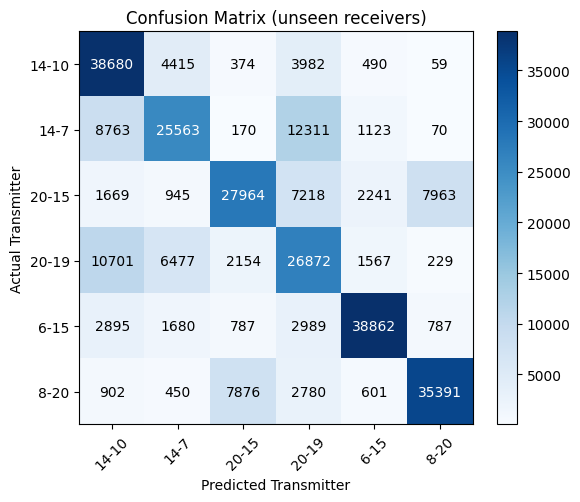

In [ ]:
plot_confusion_matrix(y_true, y_pred)